<a href="https://colab.research.google.com/github/sharasunilkottari-pixel/SDAV_Lab/blob/main/Profram3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

# **PART-1:Normal Distribution**

In [5]:
x=np.linspace(-4,4,400) #linearspace
std_normal=stats.norm(0,1) #mean=0, standard deviation=1

In [6]:
#Verify the 68-95-99.7 Rule
print("68-95-99.7 Rule:")
print(f"P(-1<Z<1)={std_normal.cdf(1)-std_normal.cdf(-1):.6f}")
print(f"P(-2<Z<2)={std_normal.cdf(2)-std_normal.cdf(-2):.6f}")
print(f"P(-3<Z<3)={std_normal.cdf(3)-std_normal.cdf(-3):.6f}")

68-95-99.7 Rule:
P(-1<Z<1)=0.682689
P(-2<Z<2)=0.954500
P(-3<Z<3)=0.997300


# **PART-2: Z-Score Standardization**

In [7]:
mu_exam,sigma_exam=70,10
for score in [60,70,80,90]:
  z=(score-mu_exam)/sigma_exam
  pct=std_normal.cdf(z)*100
  print(f"Score={score} : z={z:.2f}, Percentile={pct:.1f}%")

Score=60 : z=-1.00, Percentile=15.9%
Score=70 : z=0.00, Percentile=50.0%
Score=80 : z=1.00, Percentile=84.1%
Score=90 : z=2.00, Percentile=97.7%


# **PART-3: Exponetail Distribution**

In [11]:
lam=1.0
exp_dist=stats.expon(scale=1/lam)
print(f'Exp(lamda=1): Mean={exp_dist.mean()}, Var={exp_dist.var()}')

#Memoryless Property
print(f"P(X>2)     =  {1-exp_dist.cdf(2):.6f}")
print(f"P(X>3|X>1) =  {(1-exp_dist.cdf(3))/(1-exp_dist.cdf(1)):.6f}")

Exp(lamda=1): Mean=1.0, Var=1.0
P(X>2)     =  0.135335
P(X>3|X>1) =  0.135335


# **PART-4: Central Limit theorem**

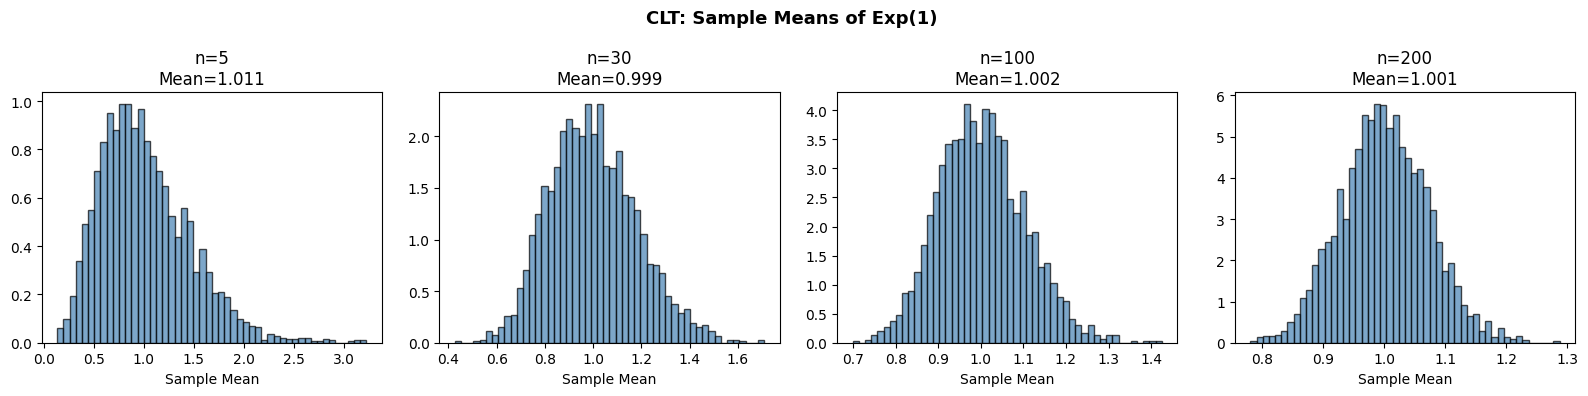

In [16]:
sample_sizes=[5,30,100,200]
fig,axes=plt.subplots(1,4,figsize=(16,4))

for i,n in enumerate(sample_sizes):
  means=[np.mean(np.random.exponential(1,n)) for _ in range(3000)]
  axes[i].hist(means,bins=50,density=True,color="steelblue",edgecolor="black",alpha=0.7)
  axes[i].set_title(f"n={n}\nMean={np.mean(means):.3f}")
  axes[i].set_xlabel("Sample Mean")

fig.suptitle("CLT: Sample Means of Exp(1) ",fontsize=13,fontweight="bold")
plt.tight_layout();plt.show()